# XGBoost Cancellation and Non-Renewal: Results Report
## Flood Risk Group Project

**Model:** XGBoost V2 · **Target:** `LAPSE` · **Development period:** 2021–2022  
**Source:** model reports committed to the project repository, retrieved on 18 November 2026.

This notebook presents the existing XGBoost results and exports the tables and figures needed for the group submission. All outputs are based on the supplied project reports. It does not fit a replacement model or require `features.parquet`.

The model-comparison companion is `08c_lapse_comparison_from_reports.ipynb`. The original training notebook remains the record of model fitting.

## 1. Setup and Input Checks
Run this notebook from the extracted submission package or from the repository's `notebooks` folder. The relative `reports` paths work in either location. Saved outputs can be viewed without running any code.

In [1]:
# Load the libraries used for report tables and figures.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'figure.dpi': 110})
GREEN, BLUE, GRAY = '#2e8b57', '#377eb8', '#757575'
SCOPE = '2021-2022'
PRIMARY_MODEL = 'XGBoost V2'

In [2]:
# Find the reports folder in the extracted package or project repository.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'reports/lapse_xgb_run.json').exists()), None)
assert ROOT is not None, 'Extract the full submission package before running this notebook.'
REPORTS = ROOT / 'reports'
run = json.loads((REPORTS / 'lapse_xgb_run.json').read_text())
xgb_deciles = pd.read_csv(REPORTS / 'lapse_xgb_test_deciles.csv').sort_values('risk_group')
xgb_confusion = pd.read_csv(REPORTS / 'lapse_xgb_test_confusion.csv')
xgb_metrics = pd.read_csv(REPORTS / 'lapse_xgb_test_metrics.csv')
xgb_overall = xgb_metrics[xgb_metrics.scope.astype(str).eq(SCOPE)]
primary_metrics = xgb_overall[xgb_overall.model.eq(PRIMARY_MODEL)].iloc[0]
N = int(xgb_deciles.rows.sum())
EVENTS = int(xgb_deciles.lapses.sum())
RATE = EVENTS / N
assert run['target'] == 'LAPSE' and run['selected_model'] == PRIMARY_MODEL
assert len(xgb_deciles) == 10 and xgb_deciles.risk_group.tolist() == list(range(1, 11))
assert int(primary_metrics.rows) == N
np.testing.assert_allclose(primary_metrics.actual_rate, RATE)
np.testing.assert_allclose(xgb_deciles.actual, xgb_deciles.lapses / xgb_deciles.rows)
np.testing.assert_allclose(xgb_deciles.share_of_lapses, xgb_deciles.lapses / EVENTS)
np.testing.assert_allclose(xgb_deciles.cumulative_capture, xgb_deciles.lapses.cumsum() / EVENTS)
np.testing.assert_allclose(primary_metrics.top_decile_capture, xgb_deciles.share_of_lapses.iloc[0])
np.testing.assert_allclose(primary_metrics.predicted_rate,
    np.average(xgb_deciles.predicted, weights=xgb_deciles.rows), rtol=1e-6)
print(f'Development population: {N:,} policy-years; {EVENTS:,} lapses ({RATE:.2%}).')

Development population: 7,105,637 policy-years; 854,084 lapses (12.02%).


In [3]:
# Verify that all input files match the recorded GitHub snapshot.
SOURCE_HASHES = {'reports/lapse_xgb_run.json': 'a970708ae6fb4b46e8523a4f747fdc3963531509', 'reports/lapse_xgb_test_deciles.csv': 'eb4491c6b0fb228ad3ca964d67d1cd4080af0251', 'reports/lapse_xgb_test_confusion.csv': '1f4d110fb5bc32504596fce7c5e241afbb2eeef6', 'reports/lapse_xgb_test_metrics.csv': '96f5433d33f7ece90b84c2870994e9c17b0411ee', 'reports/lapse_xgb_importance.csv': '8e13f46b0619883114827b99df559bef76d91f09', 'reports/lapse_xgb_test_auc.csv': '04d6ed6f7831895d3e0ad5451cf080f7be91c15b', 'reports/lapse_xgb_tuning.csv': '2ef4a0ad2e9032296a61ac8a526fd707bc8ee467', 'reports/lapse_xgb_sensitivity.csv': '64c9e4082408ee3daf3d4cef34cc396eed75c83e', 'reports/lapse_baseline_logreg_test_deciles.csv': '4a3a2477593fbd6e1e625937c2b8dd65ac928480', 'reports/lapse_rf_test_deciles.csv': 'b331c48ade6b3e12533632cb829fae0baa878bb0', 'reports/lapse_baseline_logreg_test_confusion.csv': 'e9cbe232a4aae79b3942e00a7c00fd5e81da28dc', 'reports/lapse_rf_test_confusion.csv': 'cbe4b635821c59fcdbde536c179c4780c8a72fbd', 'reports/lapse_baseline_logreg_test_metrics.csv': '60e399210209fe823135a2830fb557a47b6ad581', 'reports/lapse_rf_test_metrics.csv': '1b7dd968df843572755f203d32082fd6e3a8cad0', 'reports/lapse_rf_test_auc.csv': 'b2624c397aa80b56b9ff21a5f615ce4ce9039e6f', 'reports/lapse_rf_run.json': 'da33d8d17469b63bd796bf89ba9cd107b251e1b3'}
for relative, expected in SOURCE_HASHES.items():
    data = (ROOT / relative).read_bytes()
    observed = hashlib.sha1(f'blob {len(data)}\0'.encode() + data).hexdigest()
    assert observed == expected, f'Source changed: {relative}. Reconcile the input snapshot before rerunning.'
print(f'Verified {len(SOURCE_HASHES)} source reports against their Git blob hashes.')

Verified 16 source reports against their Git blob hashes.


In [4]:
def validate_confusions(table):
    """Reconcile reported metrics with the saved confusion counts."""
    counts = table[['TP', 'FP', 'FN', 'TN']]
    assert counts.ge(0).all().all()
    assert np.equal(counts.to_numpy(), np.floor(counts.to_numpy())).all()
    assert counts.sum(axis=1).eq(N).all()
    assert (table.TP + table.FN).eq(EVENTS).all()
    positive = table.TP + table.FP
    precision = np.divide(table.TP, positive, out=np.zeros(len(table)), where=positive > 0)
    recall = table.TP / EVENTS
    f1 = np.divide(2 * precision * recall, precision + recall,
        out=np.zeros(len(table)), where=(precision + recall) > 0)
    checks = {'flagged_share': positive / N, 'accuracy': (table.TP + table.TN) / N,
              'precision': precision, 'recall': recall, 'f1': f1, 'lift': precision / RATE}
    for metric, expected in checks.items():
        np.testing.assert_allclose(table[metric], expected, rtol=1e-9, atol=1e-12)


def save_table_image(table, title, filename):
    """Save a legible, presentation-ready image of a formatted table."""
    fig, ax = plt.subplots(figsize=(12, max(2.6, .34 * (len(table) + 3))))
    ax.axis('off')
    visual = ax.table(cellText=table.to_numpy(), colLabels=table.columns,
        cellLoc='center', loc='center')
    visual.auto_set_font_size(False)
    visual.set_fontsize(9)
    visual.auto_set_column_width(list(range(len(table.columns))))
    visual.scale(1, 1.6)
    for (row, column), cell in visual.get_celld().items():
        cell.set_edgecolor('white')
        cell.set_facecolor('#e9efeb' if row == 0 else ('#f4f4f4' if row % 2 == 0 else 'white'))
        if row == 0:
            cell.set_text_props(weight='bold')
    ax.set_title(title, fontsize=12, pad=15)
    fig.tight_layout()
    fig.savefig(REPORTS / filename, dpi=180, bbox_inches='tight')
    plt.show()


def percent_table(table, columns, decimals=1):
    result = table.copy()
    for column in columns:
        result[column] = result[column].map(lambda value: f'{value:.{decimals}%}')
    return result

## 2. Recorded Model and Evaluation Scope
The run record distinguishes the full model-training population from the samples used for preprocessing and tuning. Showing the Top 20 predictors later in this report does not restrict the fitted model to 20 inputs.

In [5]:
# Summarize the recorded run without rerunning model training.
settings = pd.DataFrame([
    ['Training years', run['train_years']], ['Model-training policy-years', f"{run['train_rows']:,}"],
    ['Preprocessing sample', f"{run['preprocessing_rows']:,}"],
    ['Tuning sample', f"{run['tuning_rows']:,}"], ['Approved original predictors', len(run['features'])],
    ['Selected model', run['selected_model']], ['Selected tree depth', run['tuned_parameters']['max_depth']],
    ['Development policy-years', f'{N:,}'], ['Development lapses', f'{EVENTS:,}'],
    ['Development lapse rate', f'{RATE:.2%}'],
    ['Final holdout evaluated in this run', 'Yes' if run['final_holdout_evaluated'] else 'No']
], columns=['Item', 'Recorded value'])
display(settings)

,Item,Recorded value
0,Training years,2014–2020
1,Model-training policy-years,"26,758,825"
2,Preprocessing sample,"1,000,000"
3,Tuning sample,"500,000"
4,Approved original predictors,68
5,Selected model,XGBoost V2
6,Selected tree depth,5
7,Development policy-years,"7,105,637"
8,Development lapses,"854,084"
9,Development lapse rate,12.02%


## 3. Course Scorecard and Confusion Matrices
The 10%, 20%, and 30% rules use probability cut-offs derived from training scores. Those cut-offs are frozen when applied to development data. Their **realized flagged shares in 2021–2022 are different from the nominal training shares**. The 0.50 rule is a reference, not the primary operating rule.

In [6]:
# Keep the same four operating-rule labels used in 06b and the RF notebook.
RULES = ['riskiest 10% in train', 'riskiest 20% in train',
         'riskiest 30% in train', 'p >= 0.5 (default)']
validate_confusions(xgb_confusion)
primary_cm = xgb_confusion[xgb_confusion.model.eq(PRIMARY_MODEL)].copy()
primary_cm = primary_cm[primary_cm.rule.isin(RULES)]
primary_cm = primary_cm.set_index('rule').loc[RULES].reset_index()
assert len(primary_cm) == 4
middle = primary_cm[primary_cm.rule.eq('riskiest 20% in train')].iloc[0]

,rule,threshold,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,lift
0,riskiest 10% in train,0.25294,0.05156,111943,254441,742141,5997112,0.85975,0.30553,0.13107,0.18344,2.54193
1,riskiest 20% in train,0.19591,0.10606,198232,555358,655852,5696195,0.82954,0.26305,0.23210,0.24661,2.18847
2,riskiest 30% in train,0.16074,0.17481,292775,949358,561309,5302195,0.78740,0.23570,0.34279,0.27934,1.96096
3,p >= 0.5 (default),0.50000,0.00279,10452,9391,843632,6242162,0.87995,0.52673,0.01224,0.02392,4.38222


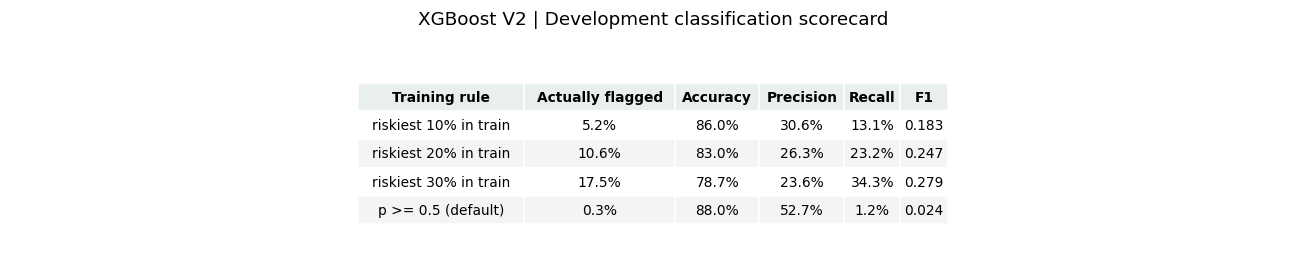

In [7]:
# Display the exact saved classification results for the primary model.
course_columns = ['rule', 'threshold', 'flagged_share', 'TP', 'FP', 'FN', 'TN',
                  'accuracy', 'precision', 'recall', 'f1', 'lift']
display(primary_cm[course_columns].round(5))
primary_cm[course_columns].to_csv(REPORTS / 'lapse_xgb_primary_course_scorecard.csv', index=False)
formatted = percent_table(primary_cm[['rule', 'flagged_share', 'accuracy', 'precision', 'recall', 'f1']],
    ['flagged_share', 'accuracy', 'precision', 'recall'])
formatted['f1'] = formatted.f1.map(lambda value: f'{value:.3f}')
formatted.columns = ['Training rule', 'Actually flagged', 'Accuracy', 'Precision', 'Recall', 'F1']
save_table_image(formatted, 'XGBoost V2 | Development classification scorecard',
    'fig_lapse_xgb_course_scorecard.png')

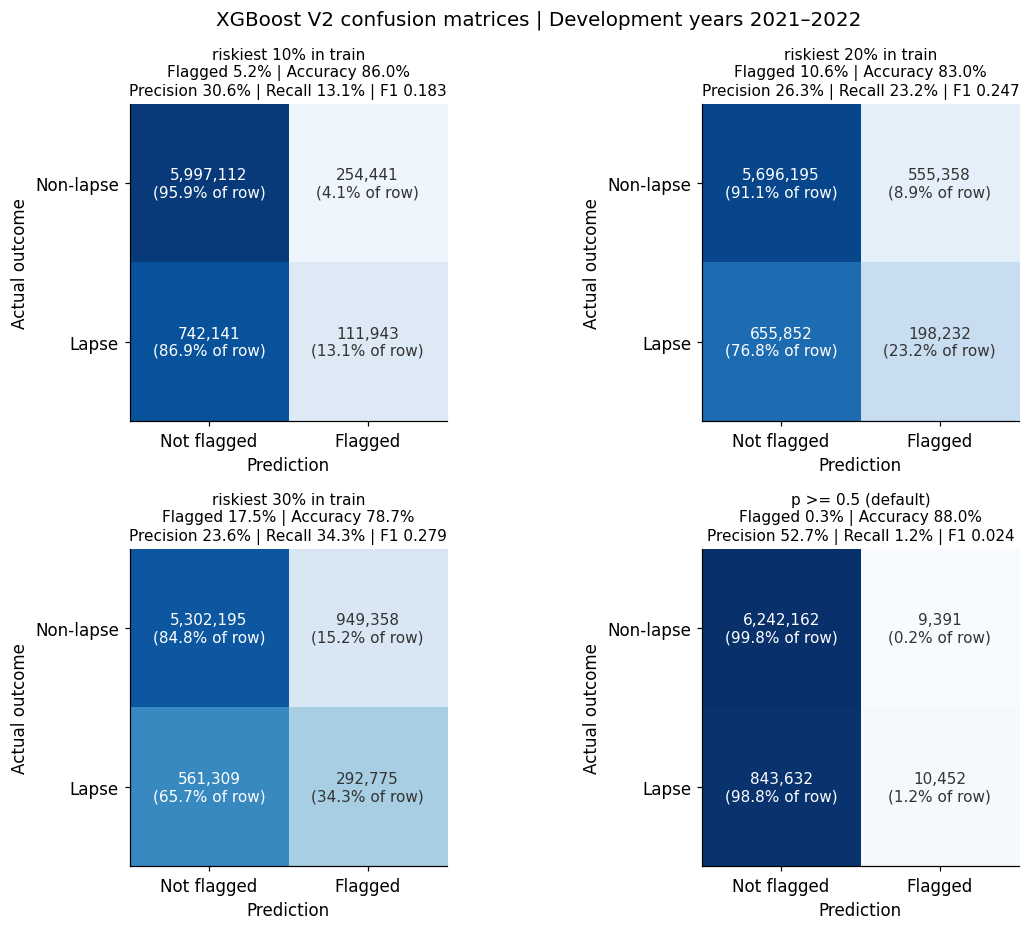

In [8]:
# Plot confusion counts and row percentages at all four saved cut-offs.
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
for ax, row in zip(axes.ravel(), primary_cm.itertuples(index=False)):
    counts = np.array([[row.TN, row.FP], [row.FN, row.TP]], dtype=int)
    shares = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(shares, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{counts[i, j]:,}\n({shares[i, j]:.1%} of row)',
                ha='center', va='center', fontsize=10,
                color='white' if shares[i, j] > .6 else '#333333')
    ax.set_xticks([0, 1], ['Not flagged', 'Flagged'])
    ax.set_yticks([0, 1], ['Non-lapse', 'Lapse'])
    ax.set(xlabel='Prediction', ylabel='Actual outcome')
    ax.set_title(f'{row.rule}\nFlagged {row.flagged_share:.1%} | Accuracy {row.accuracy:.1%}\n'
                 f'Precision {row.precision:.1%} | Recall {row.recall:.1%} | F1 {row.f1:.3f}', fontsize=10)
fig.suptitle('XGBoost V2 confusion matrices | Development years 2021–2022', fontsize=13)
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_course_confusion.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Decile Table
`risk_group = 1` is the highest predicted-risk decile; `risk_group = 10` is the lowest. Each row represents approximately 10% of development policy-years. Capture is the share of all observed lapses in that group; lift compares the group's lapse rate with the overall lapse rate.

**Requested file:** `reports/lapse_xgb_test_deciles.csv`. It is included unchanged from GitHub, including the ACS-missingness diagnostic column.

risk_group,rows,lapses,predicted,actual,share_of_lapses,cumulative_capture,lift
1,"710,564","189,611",28.14%,26.68%,22.20%,22.20%,2.22
2,"710,564","134,732",17.30%,18.96%,15.78%,37.98%,1.58
3,"710,564","112,940",13.76%,15.89%,13.22%,51.20%,1.32
4,"710,563","94,222",11.67%,13.26%,11.03%,62.23%,1.10
5,"710,564","81,755",10.11%,11.51%,9.57%,71.80%,0.96
6,"710,564","70,626",8.80%,9.94%,8.27%,80.07%,0.83
7,"710,563","61,070",7.65%,8.59%,7.15%,87.22%,0.72
8,"710,564","49,874",6.53%,7.02%,5.84%,93.06%,0.58
9,"710,564","35,751",5.12%,5.03%,4.19%,97.25%,0.42
10,"710,563","23,503",2.93%,3.31%,2.75%,100.00%,0.28


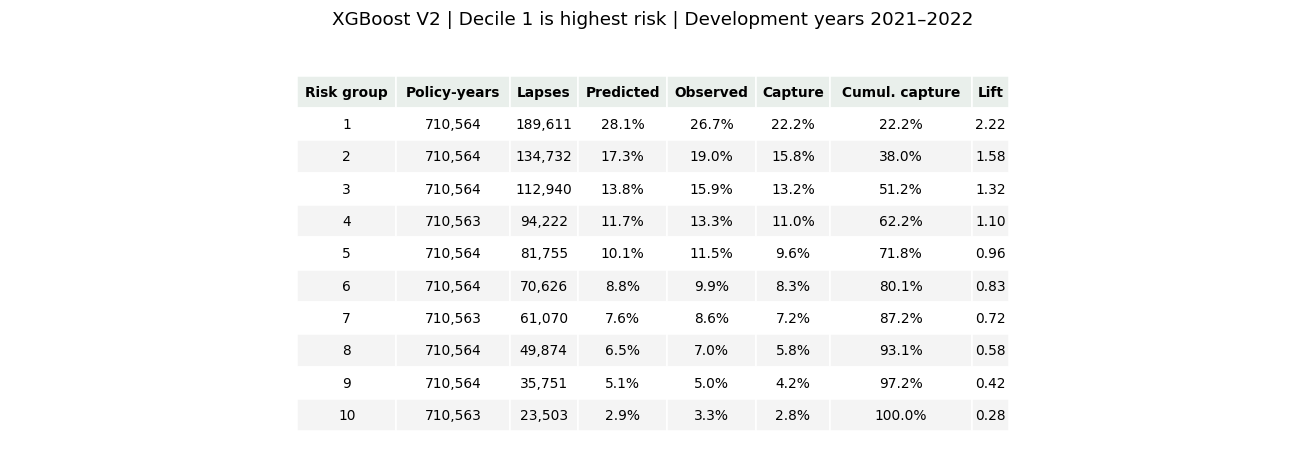

In [9]:
# Present the decile results while preserving the original requested CSV.
decile_view = xgb_deciles[['risk_group', 'rows', 'lapses', 'predicted', 'actual',
    'share_of_lapses', 'cumulative_capture', 'lift']].copy()
display(decile_view.style.format({'rows': '{:,}', 'lapses': '{:,}', 'predicted': '{:.2%}',
    'actual': '{:.2%}', 'share_of_lapses': '{:.2%}', 'cumulative_capture': '{:.2%}', 'lift': '{:.2f}'})
    .hide(axis='index'))
decile_view.to_csv(REPORTS / 'lapse_xgb_decile_summary.csv', index=False)
formatted = percent_table(decile_view, ['predicted', 'actual', 'share_of_lapses', 'cumulative_capture'])
for column in ['rows', 'lapses']:
    formatted[column] = formatted[column].map(lambda value: f'{value:,}')
formatted['lift'] = formatted.lift.map(lambda value: f'{value:.2f}')
formatted.columns = ['Risk group', 'Policy-years', 'Lapses', 'Predicted', 'Observed',
    'Capture', 'Cumul. capture', 'Lift']
save_table_image(formatted, 'XGBoost V2 | Decile 1 is highest risk | Development years 2021–2022',
    'fig_lapse_xgb_decile_table.png')

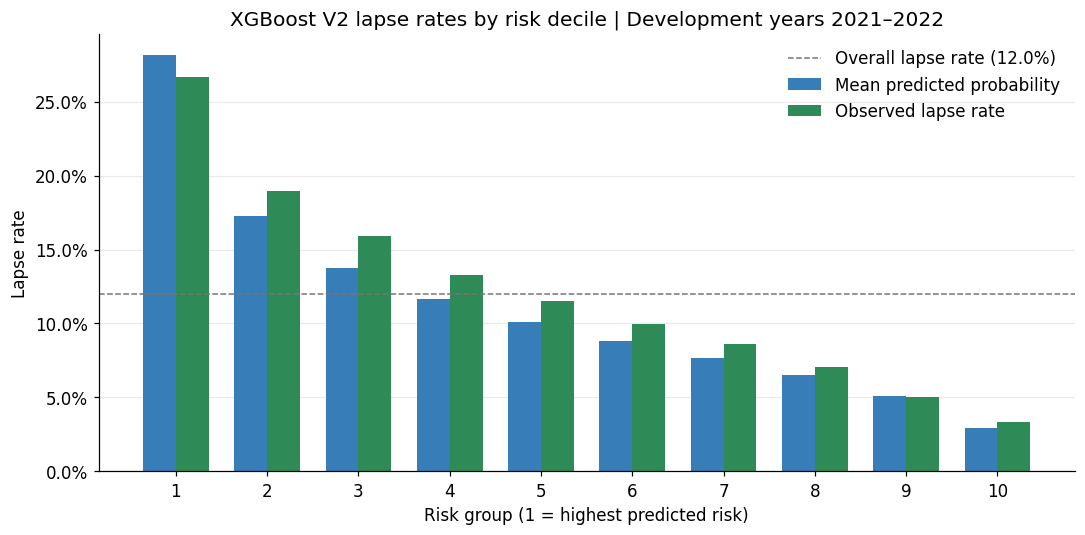

In [10]:
# Compare predicted and observed lapse rates across the ten risk deciles.
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(1, 11)
ax.bar(x - .18, xgb_deciles.predicted, width=.36, label='Mean predicted probability', color=BLUE)
ax.bar(x + .18, xgb_deciles.actual, width=.36, label='Observed lapse rate', color=GREEN)
ax.axhline(RATE, color=GRAY, linestyle='--', linewidth=1, label=f'Overall lapse rate ({RATE:.1%})')
ax.set(title='XGBoost V2 lapse rates by risk decile | Development years 2021–2022',
    xlabel='Risk group (1 = highest predicted risk)', ylabel='Lapse rate', xticks=x)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis='y', color='#e9e9e9')
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_decile_rates_report.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Top 20 Predictors
The saved importance file contains **normalized gain** for model input columns. Importance for each original predictor and its permitted `__missing` indicator is added together for this display. Thus each bar represents an original predictor rather than listing a predictor and its missingness flag separately.

This is a gain-importance chart. The repository does not supply lapse SHAP values, so these bars are not labeled as SHAP. Larger gain indicates stronger use in tree splitting, without establishing effect direction or causality.

In [11]:
# Combine saved gain for each original predictor and its permitted missingness flag.
raw_importance = pd.read_csv(REPORTS / 'lapse_xgb_importance.csv')
raw_importance = raw_importance.rename(columns={raw_importance.columns[0]: 'model_column'})
assert raw_importance.model_column.is_unique and raw_importance.importance.ge(0).all()
raw_importance['feature'] = raw_importance.model_column.str.replace(r'__missing$', '', regex=True)
assert set(raw_importance.feature).issubset(set(run['features']))
np.testing.assert_allclose(raw_importance.importance.sum(), 1, atol=1e-6)
gain = raw_importance.groupby('feature', sort=False).importance.sum().sort_values(ascending=False)
top20 = gain.head(20).rename_axis('Feature').reset_index(name='Aggregated normalized gain')
top20.insert(0, 'Rank', np.arange(1, len(top20) + 1))
assert len(top20) == 20
display(top20.style.format({'Aggregated normalized gain': '{:.4f}'}).hide(axis='index'))
top20.to_csv(REPORTS / 'lapse_xgb_top20_features.csv', index=False)
print(f"{len(run['features'])} original predictors; {len(raw_importance)} saved model columns; 20 predictors displayed.")

Rank,Feature,Aggregated normalized gain
1,new_business,0.1188
2,prev_gap_days,0.0705
3,days_since_ts_wind,0.0458
4,term_no,0.0384
5,tenure_years,0.0359
6,elevation_certificate,0.0354
7,base_flood_elevation,0.0333
8,elevation_difference,0.0293
9,coverage_to_value,0.0272
10,building_coverage,0.0264


68 original predictors; 96 saved model columns; 20 predictors displayed.


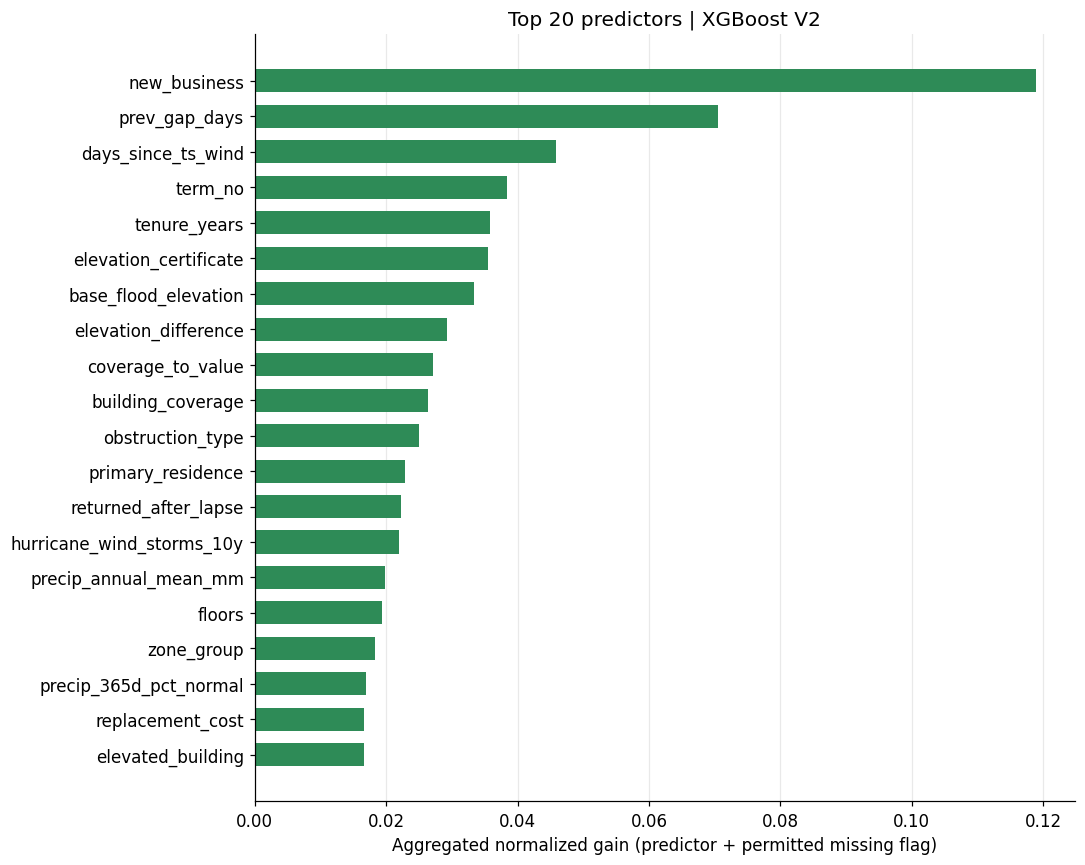

In [12]:
# Plot the Top 20 original predictors using the saved gain values.
show = top20.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(show.Feature, show['Aggregated normalized gain'], color=GREEN, height=.65)
ax.set(title='Top 20 predictors | XGBoost V2',
       xlabel='Aggregated normalized gain (predictor + permitted missing flag)', ylabel='')
ax.grid(axis='x', color='#e9e9e9')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_xgb_top20_gain.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Supplementary Probability Metrics
Log loss, Brier score, ROC-AUC, and average precision describe probability quality and ranking. Accuracy and F1 depend on the chosen classification rule and appear separately in Section 3. The tuned, uncalibrated XGBoost V2 is the primary pipeline recorded in the run metadata.

In [13]:
# Compare the saved starting, tuned, and calibrated XGBoost pipelines.
versions = xgb_overall[xgb_overall.model.str.startswith('XGBoost')][
    ['model', 'log_loss', 'brier', 'roc_auc', 'pr_auc', 'top_decile_capture']].copy()
display(versions.round(5))
versions.to_csv(REPORTS / 'lapse_xgb_probability_scorecard.csv', index=False)
yearly = xgb_metrics[xgb_metrics.model.eq(PRIMARY_MODEL) &
    xgb_metrics.scope.astype(str).isin(['2021', '2022'])]
display(yearly[['scope', 'rows', 'actual_rate', 'predicted_rate', 'log_loss', 'roc_auc']].round(5))

,model,log_loss,brier,roc_auc,pr_auc,top_decile_capture
2,XGBoost V1,0.34669,0.10108,0.67542,0.22532,0.22443
3,XGBoost V2,0.34653,0.10107,0.67674,0.22554,0.22201
4,XGBoost V2 calibrated,0.35009,0.10151,0.67658,0.22210,0.22219


,scope,rows,actual_rate,predicted_rate,log_loss,roc_auc
8,2021,3648441,0.12769,0.11040,0.35027,0.71545
13,2022,3457196,0.11229,0.11371,0.34258,0.63236


## 7. Findings and Scope

In [14]:
# State findings directly from the verified saved results.
top10, top20_decile, top30 = xgb_deciles.iloc[0], xgb_deciles.iloc[1], xgb_deciles.iloc[2]
display(Markdown(
    f"- The model was evaluated on **{N:,} development policy-years**, including **{EVENTS:,} lapses** ({RATE:.2%}).\n"
    f"- The highest-risk decile captured **{top10.share_of_lapses:.2%}** of lapses, with **{top10.actual:.2%} precision** and **{top10.lift:.2f} lift**.\n"
    f"- Targeting the highest-risk two and three deciles captured **{top20_decile.cumulative_capture:.2%}** and **{top30.cumulative_capture:.2%}** of lapses.\n"
    f"- The **riskiest 20% in train** rule actually flagged **{middle.flagged_share:.2%}** in development: "
    f"accuracy **{middle.accuracy:.2%}**, precision **{middle.precision:.2%}**, recall **{middle.recall:.2%}**, F1 **{middle.f1:.3f}**.\n"
    f"- Development ROC-AUC was **{primary_metrics.roc_auc:.3f}**. Final-holdout results are not reported here."
))

- The model was evaluated on **7,105,637 development policy-years**, including **854,084 lapses** (12.02%).
- The highest-risk decile captured **22.20%** of lapses, with **26.68% precision** and **2.22 lift**.
- Targeting the highest-risk two and three deciles captured **37.98%** and **51.20%** of lapses.
- The **riskiest 20% in train** rule actually flagged **10.61%** in development: accuracy **82.95%**, precision **26.31%**, recall **23.21%**, F1 **0.247**.
- Development ROC-AUC was **0.677**. Final-holdout results are not reported here.

### Interpretation Limits
- The decile tables and training-threshold tables answer different targeting questions; their flagged shares must not be treated as interchangeable.
- Accuracy is dominated by the non-lapse majority; assess precision, recall, and F1 together at the chosen operating rule.
- Comparisons use saved aggregate reports. Matching counts and lapse totals support consistency but do not verify individual scoring IDs.
- Gain importance does not indicate whether a feature raises or lowers risk. It does not measure a causal effect.
- The source run used the approved feature pool. This report neither selects a reduced feature set nor retunes the model.
- The 2021–2022 development results do not establish final-holdout performance or the effect of a retention campaign.

## 8. Submission Files
The package contains the unchanged `reports/lapse_xgb_test_deciles.csv`, the original XGBoost source reports, derived scorecards, and PNG figures. Source blob hashes are recorded in `source_manifest.json` and checked in Section 1.

**Project source:** [Flood Risk repository reports](https://github.com/jmsebastiancarino/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/tree/main/reports).

In [15]:
# Confirm that report generation left the requested source file unchanged.
data = (REPORTS / 'lapse_xgb_test_deciles.csv').read_bytes()
assert hashlib.sha1(f'blob {len(data)}\0'.encode() + data).hexdigest() == SOURCE_HASHES['reports/lapse_xgb_test_deciles.csv']
print('Requested file is ready: reports/lapse_xgb_test_deciles.csv')
print('Figures and additional tables have been saved in reports/.')

Requested file is ready: reports/lapse_xgb_test_deciles.csv
Figures and additional tables have been saved in reports/.
